In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"I:\Muzzamil Data Analyst\OBSIS Intership Project\OIBSIP DataAnalytics-L2-FraudDetection\creditcard.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [6]:
print("Class counts:")
print(df["Class"].value_counts())

print("\nClass percentages:")
print((df["Class"].value_counts(normalize=True) * 100).round(4))

fraud_percentage = df["Class"].mean() * 100
print(f"\nFraud percentage: {fraud_percentage:.4f}%")

Class counts:
Class
0    284315
1       492
Name: count, dtype: int64

Class percentages:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64

Fraud percentage: 0.1727%


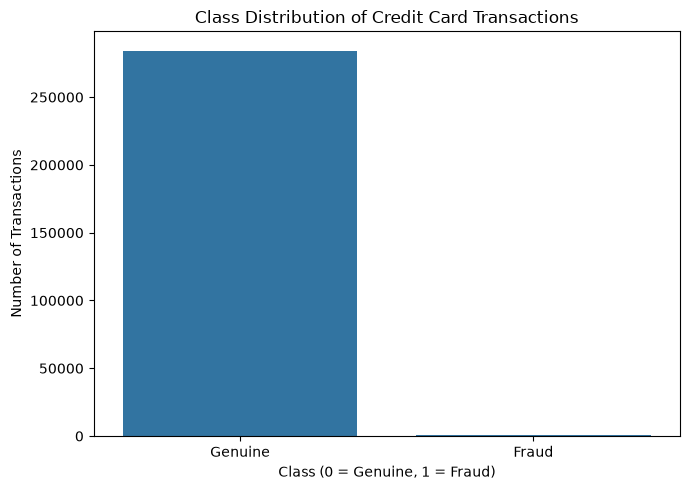

In [8]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Class")

plt.title("Class Distribution of Credit Card Transactions")
plt.xlabel("Class (0 = Genuine, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Genuine", "Fraud"])
plt.tight_layout()
plt.show()

### Class Imbalance Analysis

The dataset contains 284,807 transactions, including 284,315 genuine transactions (99.8273%) and 492 fraudulent transactions (0.1727%). This indicates a severe class imbalance.

A model that predicts every transaction as genuine would achieve approximately 99.83% accuracy but would fail to detect any fraudulent transactions. Therefore, accuracy alone is not a reliable evaluation metric for this project. Precision, recall, F1-score, and ROC-AUC will be used to evaluate model performance.

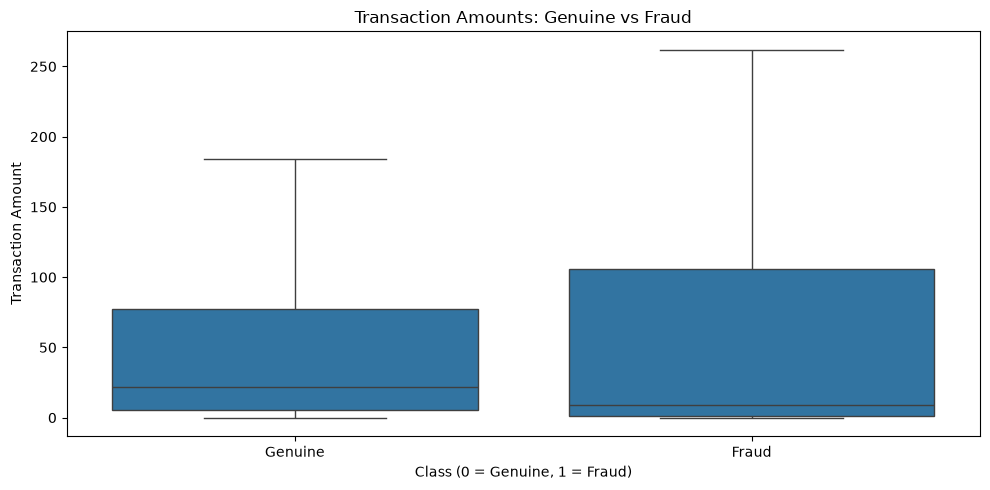

In [11]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount",
    showfliers=False
)

plt.title("Transaction Amounts: Genuine vs Fraud")
plt.xlabel("Class (0 = Genuine, 1 = Fraud)")
plt.ylabel("Transaction Amount")
plt.xticks([0, 1], ["Genuine", "Fraud"])

plt.tight_layout()
plt.show()

In [13]:
# Convert elapsed seconds into elapsed hours
df["Elapsed_Hours"] = df["Time"] / 3600

# Group transactions into 2-hour elapsed-time intervals
df["Time_Bin"] = (df["Elapsed_Hours"] // 2) * 2

print(df[["Time", "Elapsed_Hours", "Time_Bin", "Class"]].head())

   Time  Elapsed_Hours  Time_Bin  Class
0   0.0       0.000000       0.0      0
1   0.0       0.000000       0.0      0
2   1.0       0.000278       0.0      0
3   1.0       0.000278       0.0      0
4   2.0       0.000556       0.0      0


In [15]:
fraud_by_time = (
    df.groupby("Time_Bin")
      .agg(
          Total_Transactions=("Class", "count"),
          Fraud_Count=("Class", "sum"),
          Fraud_Rate=("Class", "mean")
      )
      .reset_index()
)

fraud_by_time["Fraud_Rate"] *= 100

display(fraud_by_time.head())

,Time_Bin,Total_Transactions,Fraud_Count,Fraud_Rate
0,0.0,6180,4,0.064725
1,2.0,3397,34,1.000883
2,4.0,2763,17,0.615273
3,6.0,5199,26,0.500096
4,8.0,13057,20,0.153175


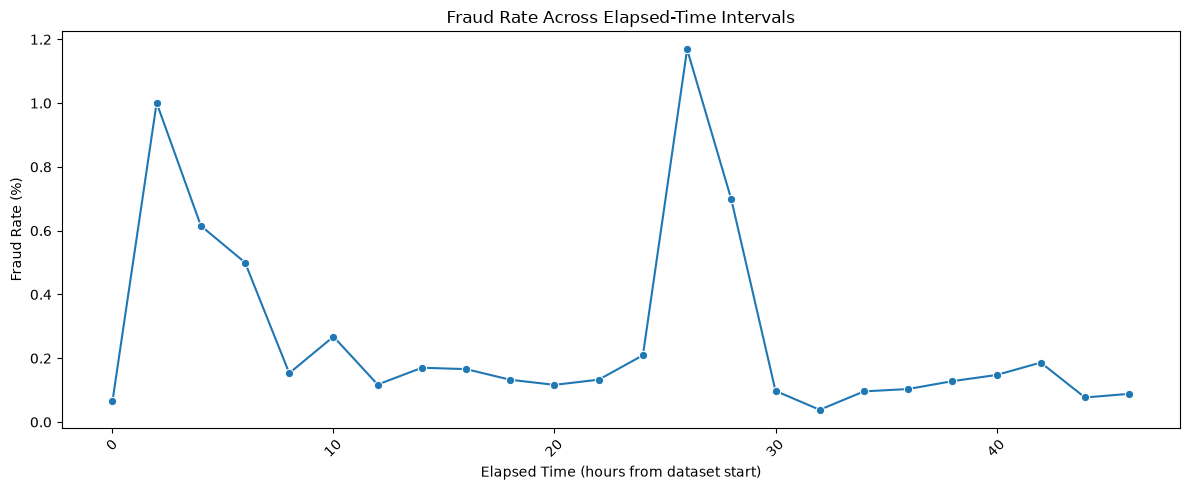

In [17]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=fraud_by_time,
    x="Time_Bin",
    y="Fraud_Rate",
    marker="o"
)

plt.title("Fraud Rate Across Elapsed-Time Intervals")
plt.xlabel("Elapsed Time (hours from dataset start)")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Why Accuracy Is Misleading in Fraud Detection

This dataset is highly imbalanced: approximately 99.83% of transactions are genuine, while only 0.17% are fraudulent.

A model that predicts every transaction as genuine could achieve approximately 99.83% accuracy while detecting none of the fraudulent transactions. Therefore, accuracy alone can give a misleading impression of model performance.

Precision measures how many transactions predicted as fraud are actually fraudulent. Recall measures how many actual fraudulent transactions the model successfully detects. The F1-score balances precision and recall, while ROC-AUC evaluates the model's ability to distinguish between the two classes across different classification thresholds.

For fraud detection, recall is especially important when missing fraudulent transactions is costly. However, precision must also be considered because too many false alarms can inconvenience customers and increase investigation costs.

In [20]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [22]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

In [24]:
# Remove the target and helper columns created during EDA
X = df.drop(columns=["Class", "Elapsed_Hours", "Time_Bin"])
y = df["Class"]

print("Features shape:", X.shape)
print("\nTarget shape:", y.shape)

Features shape: (284807, 30)

Target shape: (284807,)


In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training features: (227845, 30)
Testing features: (56962, 30)

Training class distribution:
Class
0    227451
1       394
Name: count, dtype: int64

Testing class distribution:
Class
0    56864
1       98
Name: count, dtype: int64


In [28]:
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

# Scale using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Oversample only the training set
smote = SMOTE(random_state=42)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_resampled.value_counts())

print("\nResampled training shape:", X_train_resampled.shape)

Before SMOTE:
Class
0    227451
1       394
Name: count, dtype: int64

After SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64

Resampled training shape: (454902, 30)


In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Model 1: Logistic Regression
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_resampled, y_train_resampled)

# Model 2: Random Forest
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train_resampled, y_train_resampled)

print("Both models trained successfully!")

Both models trained successfully!


In [32]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    results.append({
        "Model": name,
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.0578,0.9184,0.1088,0.9708
1,Random Forest,0.8710,0.8265,0.8482,0.9685


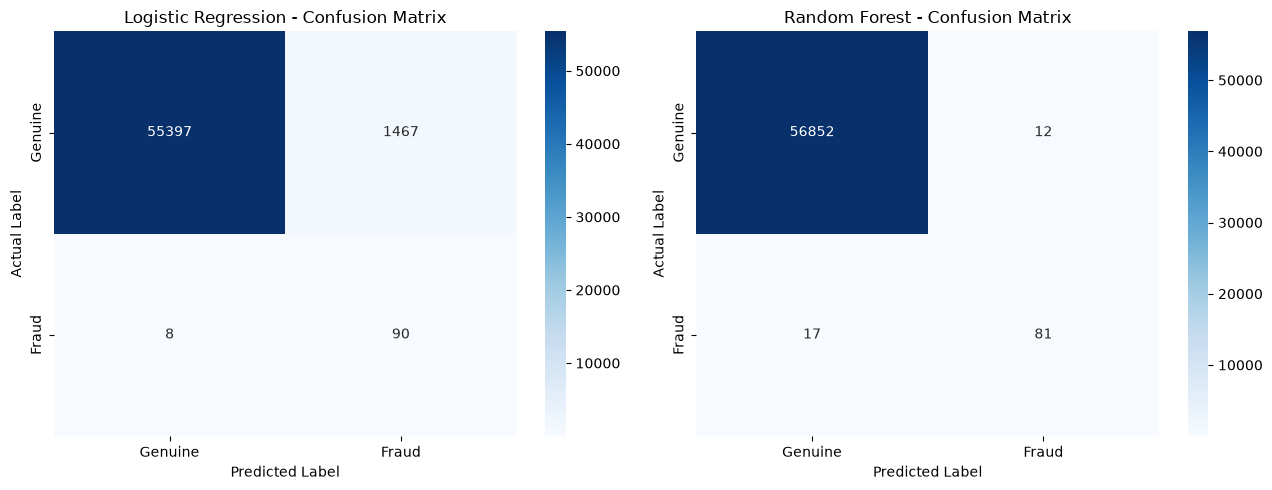

In [34]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Genuine", "Fraud"],
        yticklabels=["Genuine", "Fraud"],
        ax=ax
    )

    ax.set_title(f"{name} - Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

,Feature,Importance
14,V14,0.190334
10,V10,0.111533
4,V4,0.111358
12,V12,0.095698
17,V17,0.082916
3,V3,0.063938
11,V11,0.049284
16,V16,0.045134
2,V2,0.038536
9,V9,0.027124


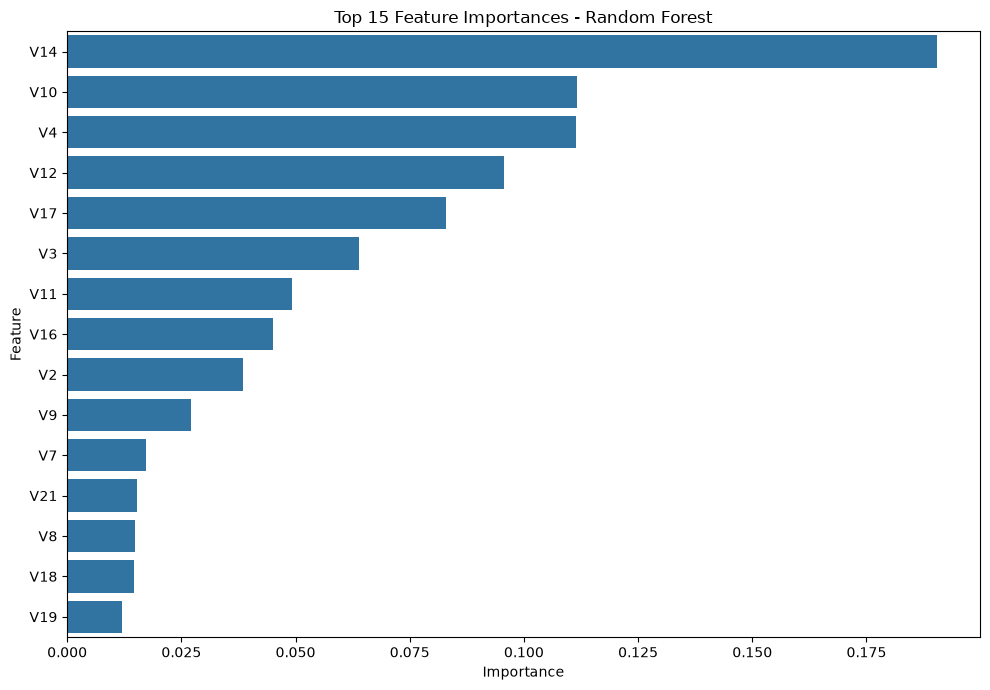

In [36]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": random_forest_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance.head(15))

plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importances - Random Forest")
plt.tight_layout()
plt.show()

### Precision vs. Recall Trade-off in Fraud Detection

Precision and recall are both important metrics for fraud detection.

**Precision** measures the proportion of transactions predicted as fraudulent that are actually fraudulent. Higher precision reduces false alarms and unnecessary transaction investigations.

**Recall** measures the proportion of actual fraudulent transactions correctly detected by the model. Higher recall helps prevent fraudulent transactions from being missed.

In this project, Logistic Regression achieved a recall of 91.84% but a precision of 5.78%. This means it detected a high proportion of fraud cases but also flagged many genuine transactions. Random Forest achieved a precision of 87.10% and a recall of 82.65%, providing a more balanced result at the current classification threshold.

Recall may be prioritized when missing fraud is very costly, while precision becomes especially important when false alarms create significant investigation costs or inconvenience customers. The final decision should depend on the financial costs of missed fraud and false positives, and the classification threshold should be tuned accordingly.

### Scalability: Handling 1 Million Transactions per Hour

One million transactions per hour is approximately 278 transactions per second. A production fraud detection system would need to process transactions reliably with low latency.

Possible improvements include:

1. **Efficient feature processing:** Use optimized data pipelines and calculate only the features required by the model.
2. **Model optimization:** Benchmark prediction latency and memory usage. Consider a lightweight model or optimized inference if needed.
3. **Parallel processing:** Deploy multiple model-serving instances behind a load balancer to distribute requests.
4. **Streaming architecture:** Use a streaming platform such as Apache Kafka to ingest and route transaction events.
5. **Monitoring:** Track latency, throughput, false positives, recall, data drift, and model performance over time.
6. **Scalable deployment:** Use containerized services and autoscaling infrastructure to handle changing transaction volumes.

The current notebook demonstrates model training and evaluation on a historical dataset. It does not prove that the model can handle one million transactions per hour. That capacity would need to be validated through realistic load testing, latency measurements, and production monitoring.

## Conclusion

In this project, I developed a machine learning pipeline to identify potentially fraudulent credit card transactions using Python, pandas, scikit-learn, imbalanced-learn, Matplotlib, and Seaborn.

The dataset contains 284,807 transactions, including 492 fraudulent transactions. Fraud represented only 0.1727% of all transactions, demonstrating a severe class imbalance. I explored the transaction data, examined transaction amounts and elapsed-time patterns, and used SMOTE to oversample the minority class in the training data.

I trained Logistic Regression and Random Forest models and evaluated them using precision, recall, F1-score, ROC-AUC, confusion matrices, and ROC curves.

Logistic Regression achieved a precision of 0.0578, recall of 0.9184, F1-score of 0.1088, and ROC-AUC of 0.9708. Random Forest achieved a precision of 0.8710, recall of 0.8265, F1-score of 0.8482, and ROC-AUC of 0.9685.

At the current classification threshold, Random Forest provided a stronger balance between precision and recall, while Logistic Regression detected a greater proportion of fraudulent transactions but generated more false positives. The choice of model depends on the relative costs of missed fraud and false alarms.

Further improvements could include threshold tuning, cross-validation, testing additional imbalance-handling methods, and conducting realistic scalability and latency tests before deployment.